## Import

In [1]:
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

## Load data TEST

In [2]:
TEST_PATH = Path("../data/processed/test.csv")

test_df = pd.read_csv(TEST_PATH)

print("Test shape:", test_df.shape)

display(test_df.head())

Test shape: (16000, 8)


,weight,height,age,gross_motor,fine_motor_adaptive,language,personal_social,dev_status
0,0.176471,0.028571,0.4,normal,normal,advanced,caution,normal
1,0.352941,0.885714,1.0,normal,advanced,advanced,normal,normal
2,0.117647,0.600000,0.4,normal,caution,delayed,delayed,suspect
3,0.000000,0.614286,0.2,delayed,normal,caution,advanced,suspect
4,0.941176,0.485714,0.4,normal,normal,advanced,delayed,suspect


## Tentukan fitur domain dan target

In [3]:
development_columns = [
    "gross_motor",
    "fine_motor_adaptive",
    "language",
    "personal_social"
]

target_column = "dev_status"

print("Development columns:")
for col in development_columns:
    print("-", col)

print("\nTarget:", target_column)

Development columns:
- gross_motor
- fine_motor_adaptive
- language
- personal_social

Target: dev_status


## Buat aturan Rule-Based

In [4]:
def rule_based_prediction(row):
    values = [
        row["gross_motor"],
        row["fine_motor_adaptive"],
        row["language"],
        row["personal_social"]
    ]

    delayed_count = values.count("delayed")
    caution_count = values.count("caution")

    if delayed_count >= 1 or caution_count >= 2:
        return "suspect"
    else:
        return "normal"

## Jalankan prediksi

In [5]:
test_df["rule_prediction"] = test_df.apply(
    rule_based_prediction,
    axis=1
)

display(
    test_df[
        development_columns +
        [target_column, "rule_prediction"]
    ].head(20)
)

,gross_motor,fine_motor_adaptive,language,personal_social,dev_status,rule_prediction
0,normal,normal,advanced,caution,normal,normal
1,normal,advanced,advanced,normal,normal,normal
2,normal,caution,delayed,delayed,suspect,suspect
3,delayed,normal,caution,advanced,suspect,suspect
4,normal,normal,advanced,delayed,suspect,suspect
5,normal,caution,delayed,delayed,suspect,suspect
6,delayed,caution,delayed,delayed,suspect,suspect
7,caution,caution,delayed,advanced,suspect,suspect
8,caution,advanced,normal,caution,suspect,suspect
9,advanced,delayed,delayed,advanced,suspect,suspect


## Evaluasi Rule-Based

In [6]:
y_test = test_df[target_column]
y_rule_pred = test_df["rule_prediction"]

accuracy = accuracy_score(y_test, y_rule_pred)

precision = precision_score(
    y_test,
    y_rule_pred,
    pos_label="suspect",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_rule_pred,
    pos_label="suspect",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_rule_pred,
    pos_label="suspect",
    zero_division=0
)

print("===== RULE-BASED BASELINE =====")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

===== RULE-BASED BASELINE =====
Accuracy : 0.9738
Precision: 0.9756
Recall   : 0.9920
F1-Score : 0.9837


## Confusion Matrix

In [7]:
cm = confusion_matrix(
    y_test,
    y_rule_pred,
    labels=["normal", "suspect"]
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 2886   318]
 [  102 12694]]


## Classification Report

In [8]:
print(
    classification_report(
        y_test,
        y_rule_pred,
        labels=["normal", "suspect"],
        target_names=["normal", "suspect"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      normal       0.97      0.90      0.93      3204
     suspect       0.98      0.99      0.98     12796

    accuracy                           0.97     16000
   macro avg       0.97      0.95      0.96     16000
weighted avg       0.97      0.97      0.97     16000



## Cek apakah ada ketidaksesuaian

In [9]:
mismatch = test_df[
    test_df[target_column] != test_df["rule_prediction"]
]

print("Jumlah mismatch:", len(mismatch))

if len(mismatch) == 0:
    print("✅ Semua label sesuai dengan rule-based.")
else:
    print("⚠️ Ditemukan ketidaksesuaian.")

    display(
        mismatch[
            development_columns +
            [target_column, "rule_prediction"]
        ]
    )

Jumlah mismatch: 420
⚠️ Ditemukan ketidaksesuaian.


,gross_motor,fine_motor_adaptive,language,personal_social,dev_status,rule_prediction
30,normal,caution,delayed,advanced,normal,suspect
63,delayed,delayed,delayed,caution,normal,suspect
75,delayed,advanced,delayed,advanced,normal,suspect
156,normal,normal,caution,normal,suspect,normal
173,caution,advanced,advanced,delayed,normal,suspect
...,...,...,...,...,...,...
15682,delayed,advanced,caution,caution,normal,suspect
15772,delayed,advanced,advanced,normal,normal,suspect
15950,caution,normal,caution,caution,normal,suspect
15973,normal,caution,delayed,caution,normal,suspect


## Kesimpulan otomatis

In [10]:
print("=" * 60)
print("CHECKPOINT 3.6 — RULE-BASED BASELINE")
print("=" * 60)

print(f"\nAccuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

print(f"\nJumlah mismatch: {len(mismatch)}")

if len(mismatch) == 0:
    print("\nKESIMPULAN:")
    print("✅ dev_status dapat direproduksi sepenuhnya")
    print("   menggunakan empat domain perkembangan.")
    print("✅ Hasil 100% CatBoost konsisten dengan")
    print("   struktur deterministik label dataset.")
else:
    print("\nKESIMPULAN:")
    print("⚠️ Terdapat label yang tidak sesuai dengan rule-based.")
    print("Perlu dilakukan investigasi sebelum melanjutkan.")

CHECKPOINT 3.6 — RULE-BASED BASELINE

Accuracy : 0.9738
Precision: 0.9756
Recall   : 0.9920
F1-Score : 0.9837

Jumlah mismatch: 420

KESIMPULAN:
⚠️ Terdapat label yang tidak sesuai dengan rule-based.
Perlu dilakukan investigasi sebelum melanjutkan.


## Simpan

In [11]:
OUTPUT_DIR = Path("../outputs/metrics")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

rule_metrics = pd.DataFrame([{
    "model": "Rule-Based Baseline",
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "mismatch_count": len(mismatch)
}])

rule_metrics.to_csv(
    OUTPUT_DIR / "rule_based_baseline_metrics.csv",
    index=False
)

print("✅ Hasil disimpan:")
print(OUTPUT_DIR / "rule_based_baseline_metrics.csv")

✅ Hasil disimpan:
..\outputs\metrics\rule_based_baseline_metrics.csv


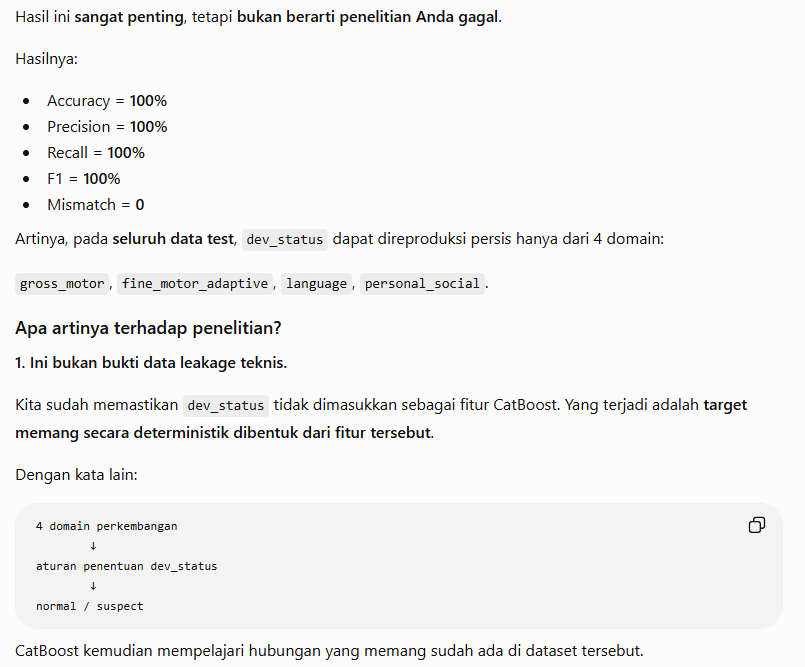

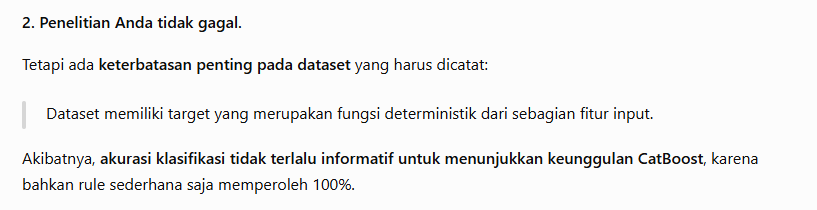